# Modélisation

In [1]:
from main import load_dataset

from pathlib import Path
from datetime import datetime
import json
import math

import numpy as np

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec

import pandas as pd

import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, roc_curve,
    confusion_matrix
)

RANDOM_STATE = 42
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok = True)

## Rappels sur les metrics

### Metrics

| Nom | Définition | Formule |
|---|---|---|
| Accuracy (exactitude) | Proportion de prédictions correctes sur l'ensemble des échantillons. Trompeuse si les classes sont déséquilibrées. | (TP + TN) / (TP + TN + FP + FN) |
| Précision | Parmi les individus prédits « Survivant », proportion qui le sont réellement. Mesure le coût des faux positifs. | TP / (TP + FP) |
| Rappel (sensibilité, TPR) | Parmi les vrais survivants, proportion détectée par le modèle. Mesure le coût des faux négatifs. | TP / (TP + FN) |
| Score F1 | Moyenne harmonique de la précision et du rappel. Utile pour résumer l'équilibre entre les deux. | 2 × (Précision × Rappel) / (Précision + Rappel) = 2TP / (2TP + FP + FN) |
| AUC ROC | Aire sous la courbe ROC. Probabilité qu'un survivant tiré au hasard reçoive un score plus élevé qu'un non-survivant. 0,5 = hasard, 1 = parfait. Indépendante du seuil. | ∫ TPR d(FPR) |
| Courbe ROC (fpr, tpr) | Points (FPR, TPR) obtenus en faisant varier le seuil de décision de 0 à 1. | FPR = FP / (FP + TN) ; TPR = TP / (TP + FN) |
| Matrice de confusion | Tableau croisant classes réelles et prédites. Sous scikit-learn : `[[TN, FP], [FN, TP]]`. | Comptages : TN, FP, FN, TP |
| Rapport de classification | Précision, rappel, F1 et support calculés pour chaque classe, plus les moyennes globales. | Voir les moyennes ci-dessous |

### Moyennes du `classification_report`

| Élément | Définition | Formule |
|---|---|---|
| Support | Nombre d'échantillons réels de chaque classe. | n_classe |
| Macro avg | Moyenne simple des métriques par classe, sans tenir compte de leur taille. | (M₀ + M₁) / 2 |
| Weighted avg | Moyenne des métriques par classe, pondérée par le support. | Σ (nₖ × Mₖ) / N |
| Accuracy (dans le rapport) | Même valeur que `test_accuracy`. | (TP + TN) / N |

### Indicateurs complémentaires pertinents

| Nom | Définition | Formule |
|---|---|---|
| Spécificité (TNR) | Proportion de vrais négatifs correctement identifiés. | TN / (TN + FP) |
| FPR (taux de faux positifs) | Proportion de négatifs classés à tort comme positifs. Axe X de la courbe ROC. | FP / (FP + TN) = 1 − Spécificité |
| FNR (taux de faux négatifs) | Proportion de positifs manqués. | FN / (FN + TP) = 1 − Rappel |
| NPV (valeur prédictive négative) | Parmi les prédits « Mort », proportion qui le sont réellement. | TN / (TN + FN) |
| Balanced accuracy | Moyenne du rappel et de la spécificité. Plus fiable que l'accuracy en cas de déséquilibre. | (TPR + TNR) / 2 |
| F-beta | Généralisation du F1 pondérant le rappel β fois plus que la précision. | (1 + β²) × (P × R) / (β² × P + R) |
| MCC (coefficient de Matthews) | Corrélation entre prédictions et réalité. Robuste au déséquilibre, de −1 à 1. | (TP×TN − FP×FN) / √((TP+FP)(TP+FN)(TN+FP)(TN+FN)) |
| Cohen's kappa | Accord entre prédictions et réalité, corrigé de l'accord dû au hasard. | (p₀ − pₑ) / (1 − pₑ) |
| Log loss (entropie croisée) | Pénalise les probabilités prédites éloignées de la vérité. Évalue la qualité des probabilités, pas seulement des classes. | −(1/N) Σ [y·log(p) + (1−y)·log(1−p)] |
| Brier score | Erreur quadratique moyenne entre probabilités prédites et réalité. Plus bas = mieux. | (1/N) Σ (p − y)² |
| PR AUC (average precision) | Aire sous la courbe précision-rappel. Plus informative que l'AUC ROC quand la classe positive est rare. | Σ (Rₙ − Rₙ₋₁) × Pₙ |
| Courbe de calibration | Compare les probabilités prédites aux fréquences observées. | Fréquence observée vs probabilité moyenne par intervalle |

Notation : TP = vrais positifs, TN = vrais négatifs, FP = faux positifs, FN = faux négatifs (classe positive = « Survivant »).

## Code

In [25]:
def fill_features(df):
    df = df.copy()

    df["Age"] = df.groupby(["Pclass", "Sex"]).Age.transform(lambda s: s.fillna(s.median()))
    df["Embarked"] = df.Embarked.fillna(df.Embarked.mode()[0])
    
    return df

def remove_features(df):
    df = df.copy()

    del df["Name"]
    del df["PassengerId"]
    del df["Cabin"]
    del df["Ticket"]
    
    return df

def add_features(df):
    df = df.copy()

    df["Title"] = df.Name.str.extract(r",\s*([^\.]+)\.")
    df["Title"] = df.Title.replace({
        "Mlle": "Miss", 
        "Ms": "Miss", 
        "Mme": "Mrs"
    })
    title_counts = df.Title.value_counts()
    df["Title"] = df.Title.where(df.Title.isin(title_counts[title_counts >= 10].index), "Other")
    
    df["FamilySize"] = df.SibSp + df.Parch + 1
    df["isAlone"] = df.FamilySize.apply(lambda x: 1 if x == 0 else 0)
    df["HasCabin"] = df.Cabin.notna().astype(int)
    
    return df

In [3]:
def train_model(name, model, param_grid, X_train, y_train):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state = RANDOM_STATE)
    
    search = GridSearchCV(
        model,
        param_grid = param_grid,
        cv = cv,
        scoring = "accuracy"
    )
    
    search.fit(X_train, y_train)

    joblib.dump(search.best_estimator_, MODELS_DIR / f"{name}.joblib")

    info = {
        "name": name,
        "date": datetime.now().isoformat(timespec="seconds"),
        "cv_best_params": search.best_params_,
        "metrics" : {
            "cv_best_accuracy": search.best_score_
        }
    }
    
    (MODELS_DIR / f"{name}.json").write_text(json.dumps(info, indent = 2))

    return search

In [4]:
def evaluate_model(name, X_test, y_test, split = "test", verbose = True):
    model = joblib.load(MODELS_DIR / f"{name}.joblib")

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_proba)

    metrics = {
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_precision": precision_score(y_test, y_pred),
        "test_recall": recall_score(y_test, y_pred),
        "test_f1": f1_score(y_test, y_pred),
        "test_roc_auc": roc_auc_score(y_test, y_proba),
        "test_roc_curve": {"fpr": fpr.tolist(), "tpr": tpr.tolist()},
        "test_confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
        "test_classification_report": classification_report(
            y_test, y_pred, output_dict = True
        ),
    }

    path = MODELS_DIR / f"{name}.json"
    info = json.loads(path.read_text()) if path.exists() else {"name": name}
    info.setdefault("metrics", {})[split] = metrics
    path.write_text(json.dumps(info, indent = 2, default = float))

    return metrics

In [5]:
def display_test_metrics(metrics, labels=("Mort", "Survivant"), model = None, X_eval = None, y_eval = None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    cm = np.array(metrics["test_confusion_matrix"])
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        cmap="Blues", ax=axes[0], colorbar=False
    )
    axes[0].set_title("Matrice de confusion")
    axes[0].grid(False)

    # ROC curve: stored points if available, otherwise recompute from the model
    if "test_roc_curve" in metrics:
        RocCurveDisplay(
            fpr=np.array(metrics["test_roc_curve"]["fpr"]),
            tpr=np.array(metrics["test_roc_curve"]["tpr"]),
            roc_auc=metrics["test_roc_auc"],
        ).plot(ax=axes[1])
    elif model is not None:
        RocCurveDisplay.from_estimator(model, X_eval, y_eval, ax=axes[1])
        
    else:
        axes[1].text(0.5, 0.5, "ROC indisponible\n(re-run evaluate_model)",
                     ha="center", va="center")
        axes[1].set_axis_off()

    if axes[1].axison:
        axes[1].plot([0, 1], [0, 1], "k--", label="Hasard")
        axes[1].set_title("Courbe ROC")
        axes[1].legend(loc="lower right")

    fig.suptitle(
        f"Accuracy {metrics['test_accuracy']:.3f} | Precision {metrics['test_precision']:.3f} | "
        f"Recall {metrics['test_recall']:.3f} | F1 {metrics['test_f1']:.3f} | AUC {metrics['test_roc_auc']:.3f}",
        fontsize=11,
    )
    
    plt.tight_layout()
    plt.show()

In [6]:
def compare_models(names, X_test, y_test, labels=("Mort", "Survivant"), cm_cols=2):
    results = {name: evaluate_model(name, X_test, y_test) for name in names}

    keys = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]
    table = pd.DataFrame({
        name: {k.replace("test_", ""): m[k] for k in keys}
        for name, m in results.items()
    })
    display(table.round(3).style.highlight_max(axis=1, color="lightgreen"))

    n = len(names)
    cm_cols = min(cm_cols, n)
    cm_rows = math.ceil(n / cm_cols)

    fig = plt.figure(figsize=(8 + 4 * cm_cols, max(5, 4 * cm_rows)))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, cm_cols * 0.8])

    ax_roc = fig.add_subplot(gs[0])
    for name, m in results.items():
        ax_roc.plot(
            m["test_roc_curve"]["fpr"],
            m["test_roc_curve"]["tpr"],
            label=f"{name} (AUC = {m['test_roc_auc']:.3f})",
        )
    ax_roc.plot([0, 1], [0, 1], "k--", label="Hasard")
    ax_roc.set_xlabel("Taux de faux positifs")
    ax_roc.set_ylabel("Taux de vrais positifs")
    ax_roc.set_title("Courbes ROC")
    ax_roc.legend(loc="lower right")

    sub = GridSpecFromSubplotSpec(cm_rows, cm_cols, subplot_spec=gs[1])
    for i, (name, m) in enumerate(results.items()):
        ax = fig.add_subplot(sub[i // cm_cols, i % cm_cols])
        ConfusionMatrixDisplay(
            np.array(m["test_confusion_matrix"]), display_labels=labels
        ).plot(cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(name)
        ax.grid(False)

    fig.suptitle("Comparaison des modèles", fontsize=13)
    plt.tight_layout()
    plt.show()

In [7]:
def get_model_feature_importance(model, feature_names, top_n = 20, plot=True):
    if isinstance(model, Pipeline):
        estimator = model[-1]
        try:
            names = model[:-1].get_feature_names_out()
        except Exception:
            names = None
    else:
        estimator = model
        names = None

    # Importance values
    if hasattr(estimator, "feature_importances_"):
        values = estimator.feature_importances_
    elif hasattr(estimator, "coef_"):
        coefs = np.atleast_2d(estimator.coef_)
        values = coefs[0] if coefs.shape[0] == 1 else np.abs(coefs).mean(axis=0)
    else:
        raise ValueError(f"No importance available for {type(estimator).__name__}")

    if names is None:
        names = getattr(estimator, "feature_names_in_", None)
        
    if names is None:
        names = [feature_names[i] for i in range(len(feature_names))]

    importances = pd.Series(values, index=names)
    importances = importances.reindex(importances.abs().sort_values().index).tail(top_n)

    if plot:
        importances.plot.barh(figsize=(8, 6))
        plt.title(f"{type(estimator).__name__} - top {top_n}")
        plt.xlabel("Importance")
        plt.tight_layout()
        plt.show()

    return importances

## 1. Préparation des données

In [8]:
# NB :
# Ordinal : The input to this transformer should be an array-like of integers or strings, denoting the values taken on by categorical (discrete) features. The features are converted to ordinal integers. This results in a single column of integers (0 to n_categories - 1) per feature.
# OneHot : The input to this transformer should be an array-like of integers or strings, denoting the values taken on by categorical (discrete) features. The features are encoded using a one-hot (aka ‘one-of-K’ or ‘dummy’) encoding scheme. This creates a binary column for each category and returns a sparse matrix or dense array (depending on the sparse_output parameter).

preprocessor = Pipeline([
    ("fill_features", FunctionTransformer(fill_features)),
    ("add_features", FunctionTransformer(add_features)),
    ("remove_features", FunctionTransformer(remove_features)),
    ("encode", ColumnTransformer([
        ("Sex", OrdinalEncoder(categories=[["female", "male"]]), ["Sex"]),
        ("ohe", Pipeline([
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), ["Embarked", "Title"]),
        ("num", "passthrough", ["Pclass", "FamilySize", "HasCabin", "Fare", "Age", "isAlone"]),
    ], remainder="passthrough" )),
])

titanic_original_df = load_dataset()
X = titanic_original_df.drop(columns="Survived")
y = titanic_original_df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = RANDOM_STATE, stratify = y
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = list(preprocessor.named_steps["encode"].get_feature_names_out())

> Le choix de la metric principale s'est porté sur l'`accuracy` (métrique officielle de la compétition Kaggle + le déséquilibre est modéré (environ 38 % de survivants, 62 % de morts), donc elle reste lisible + il n’y a pas de coût asymétrique entre faux positifs et faux négatifs. Rater un survivant n’est pas plus grave que rater un mort, ce qui écarte le rappel ou la précision comme objectif unique.)

## 2. Implémentation des modélisations

### 2.1 La régression logistique (Logistic Regression)

In [9]:
from sklearn.linear_model import LogisticRegression

In [10]:
logistic_regression_classifier = LogisticRegression(random_state = RANDOM_STATE)

logistic_regression_param_grid = {
    "max_iter": [5000]
}

logistic_regression_model = train_model(
    name = "logistic_regression",
    model = logistic_regression_classifier,
    param_grid = logistic_regression_param_grid,
    X_train = X_train_prep,
    y_train = y_train
)

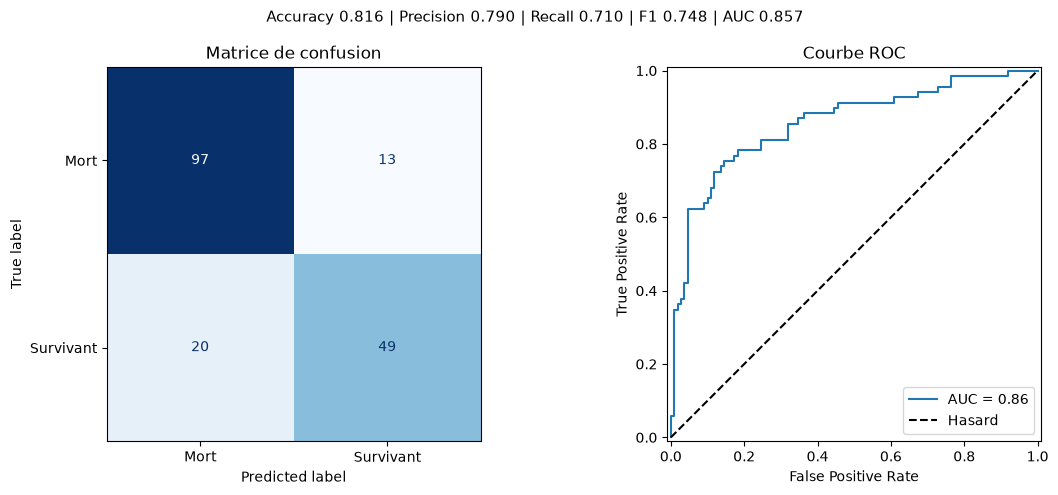

In [11]:
logistic_regression_metrics = evaluate_model(
    name = "logistic_regression",
    X_test = X_test_prep,
    y_test = y_test
)

display_test_metrics(
    logistic_regression_metrics
)

### 2.2 Random Forest

In [12]:
from sklearn.ensemble import RandomForestClassifier

In [13]:
random_forest_classifier = RandomForestClassifier(random_state = RANDOM_STATE)

random_forst_param_grid = {
    "min_samples_leaf": [1, 2, 3, 5, 8, 10, 15],
    "max_features": ["sqrt", 0.3, 0.5, 0.7, None],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

random_forest_model = train_model(
    name = "random_forest",
    model = random_forest_classifier,
    param_grid = random_forst_param_grid,
    X_train = X_train_prep,
    y_train = y_train
)

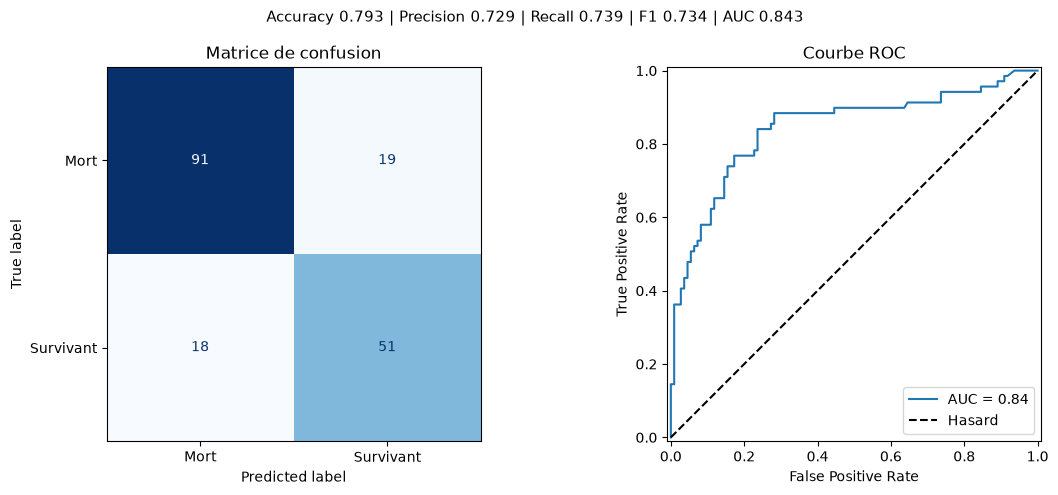

In [14]:
random_forest_metrics = evaluate_model(
    name = "random_forest",
    X_test = X_test_prep,
    y_test = y_test
)

display_test_metrics(
    random_forest_metrics
)

### 2.3 Xgboost

In [15]:
from xgboost import XGBClassifier

In [16]:
xgb_classifier = XGBClassifier(
    random_state = RANDOM_STATE,
)

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1, 0.3],
    "subsample": [0.7, 1.0],
    "colsample_bytree": [0.7, 1.0],
}

search = train_model(
    name="xgb_classifier",
    model = xgb_classifier,
    param_grid = xgb_param_grid,
    X_train = X_train_prep,
    y_train = y_train
)

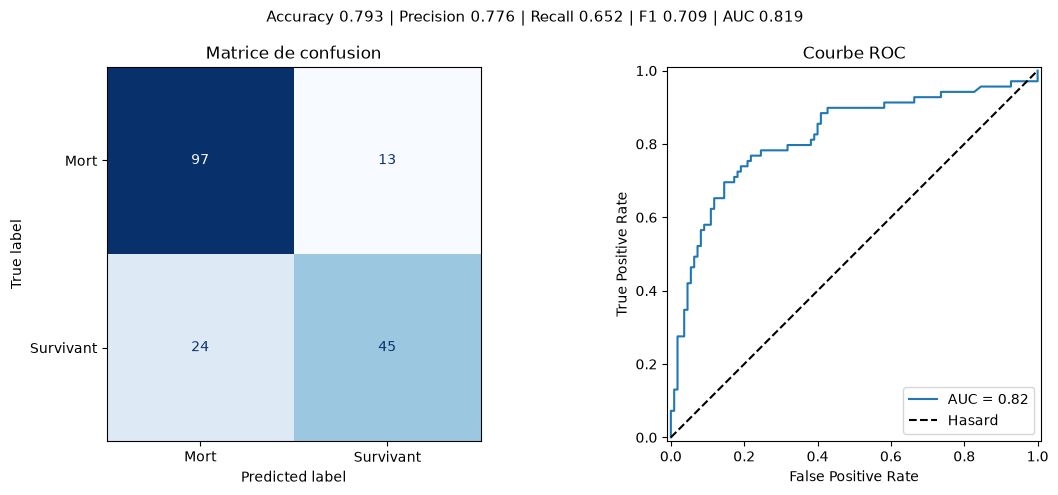

In [17]:
xgb_classifier_metrics = evaluate_model(
    name = "xgb_classifier",
    X_test = X_test_prep,
    y_test = y_test
)

display_test_metrics(
    xgb_classifier_metrics
)

### 2.4 Gradient boosting

In [18]:
from sklearn.ensemble import GradientBoostingClassifier

In [19]:
gradient_boosting_classifier = GradientBoostingClassifier(random_state=RANDOM_STATE)

gradient_boosting_param_grid = {
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "min_samples_leaf": [1, 5, 10],
}

search = train_model(
    name="gradient_boosting",
    model = gradient_boosting_classifier,
    param_grid = gradient_boosting_param_grid,
    X_train = X_train_prep,
    y_train = y_train
)

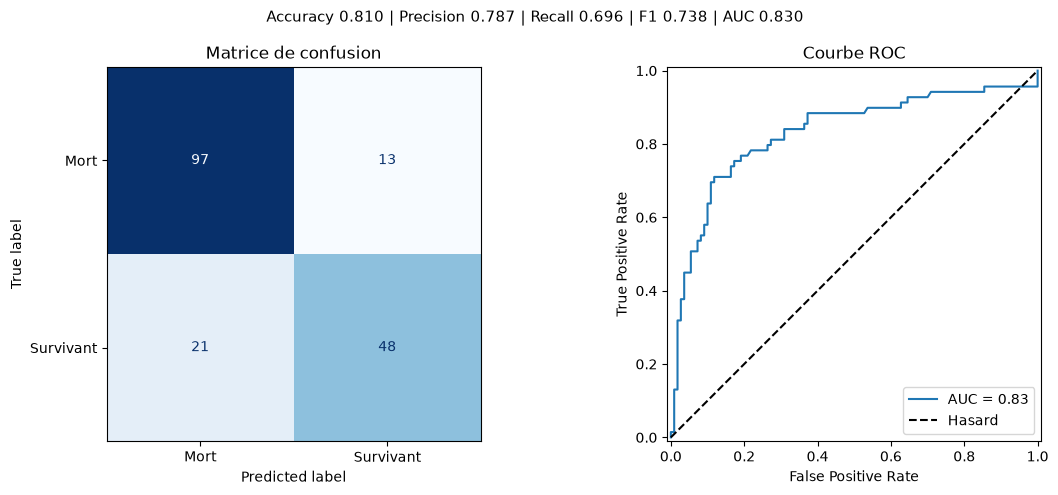

In [20]:
gradient_boosting_metrics = evaluate_model(
    name = "gradient_boosting",
    X_test = X_test_prep,
    y_test = y_test
)

display_test_metrics(
    gradient_boosting_metrics
)

## 3. Comparaison des modèles

,logistic_regression,random_forest,xgb_classifier,gradient_boosting
accuracy,0.816000,0.793000,0.793000,0.810000
precision,0.790000,0.729000,0.776000,0.787000
recall,0.710000,0.739000,0.652000,0.696000
f1,0.748000,0.734000,0.709000,0.738000
roc_auc,0.857000,0.843000,0.819000,0.830000


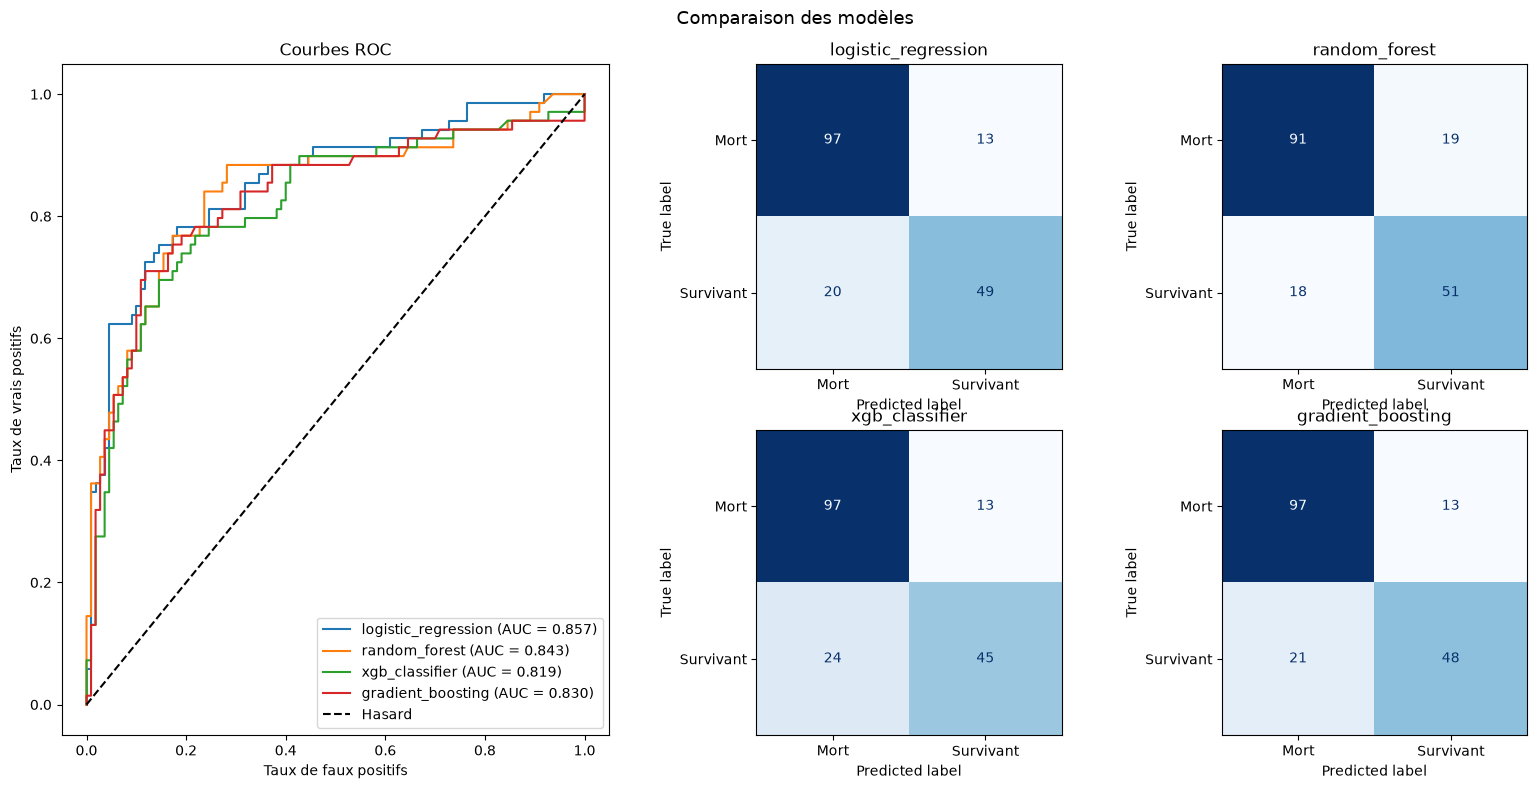

In [21]:
compare_models(
    names = ["logistic_regression", "random_forest", "xgb_classifier", "gradient_boosting"],
    X_test = X_test_prep,
    y_test = y_test
)

## 4. Conclusions

> " Quels facteurs ont réellement influencé les chances de survie des passagers ? "

Le sexe et la classe sociale ont été les facteurs décisifs. L’âge (surtout l’enfance) et la composition de la famille ont joué un rôle secondaire. Le port d’embarquement n’a pas d’effet propre.

1. Sexe (avec le titre, qui en est le reflet)

L’EDA donne 74 % de survie chez les femmes contre 19 % chez les hommes.
Sex et Title_Mr sont en tête dans les quatre modèles. Les deux variables sont redondantes (Title résume sexe, âge et statut marital), donc leur importance se partage entre elles.

2. Classe sociale (Pclass, Fare, HasCabin)

La survie passe de 63 % en 1ère classe à 47 % en 2nde et 24 % en 3ème.
L’interaction avec le sexe est forte. 92 à 97 % des femmes de 1ère et 2nde classe ont survécu, contre 50 % en 3ème. Chez les hommes, seule la 1ère classe dépasse nettement 15 % (37 %).
Ces trois variables mesurent la même chose, la richesse. Dans la régression logistique, Fare a un coefficient quasi nul parce que Pclass et HasCabin portent déjà l’information. Dans les arbres, Fare ressort très haut.

3. Âge

Les moins de 12 ans survivent à 58 %, les plus de 60 ans à 23 %. Entre les deux, l’effet est faible.
La corrélation linéaire est de seulement −0,08 : l’effet est non linéaire. C’est le titre Master (57 %) qui le capte le mieux.

4. Taille de la famille

L’effet n’est pas monotone. La survie est maximale à 2–4 personnes (55 à 72 %) et s’effondre à partir de 5. Voyager seul donne 30 %.
Les effectifs des grandes familles sont très faibles.

5. Port d’embarquement

Cherbourg a 55 % de survie contre 34 % à Southampton. Cet écart vient de la composition par classe : 51 % de 1ère classe à Cherbourg, 93 % de 3ème à Queenstown.
Le modèle ne lui accorde qu’un poids marginal.

Les modèles prédisent à 79–82 % avec des variables simples. L’échantillon de test ne compte que 179 passagers, donc les écarts entre modèles ne sont pas significatifs. La régression logistique n’est pas moins bonne que les modèles d’arbres, ce qui est cohérent avec des effets assez simples.

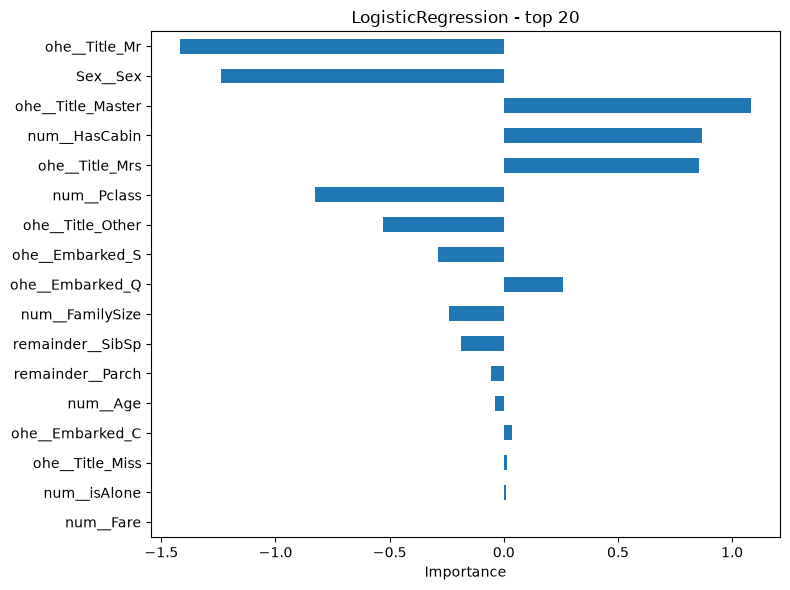

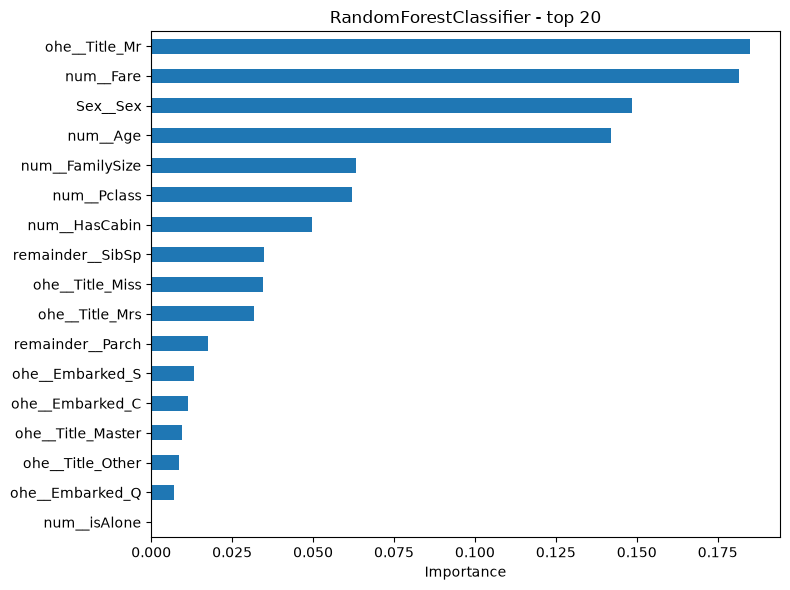

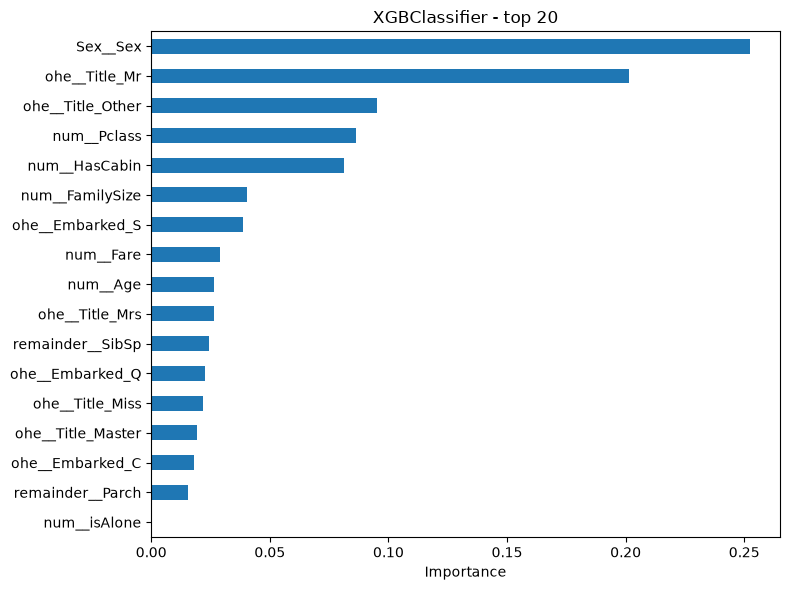

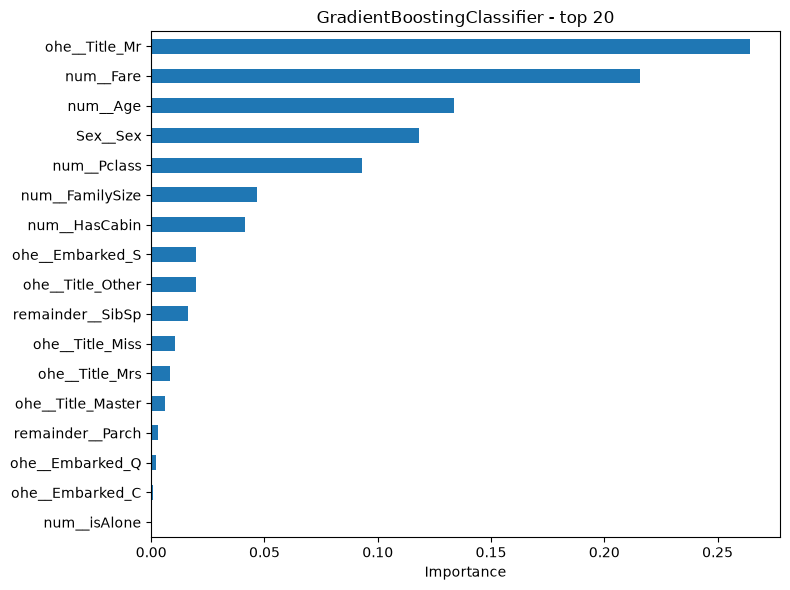

In [24]:
for model_name in ["logistic_regression", "random_forest", "xgb_classifier", "gradient_boosting"]:
    get_model_feature_importance(
        model = joblib.load(Path(MODELS_DIR, f"{model_name}.joblib")),
        feature_names = feature_names
    )